In [1]:
import sys
sys.path.append("..")
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colors
from scipy.interpolate import griddata, RegularGridInterpolator, CubicSpline
import pygeode as pyg
import os, glob
from jfunctions import *
from mpas_funcs import *
import scipy.ndimage
from matplotlib.lines import Line2D
from tropopause import *
import pandas as pd
from calendar import isleap
from matplotlib.ticker import MaxNLocator
import matplotlib.animation as animation

%matplotlib widget

save = False
#save_dir='/home/cwp29/tmp/mpas/T_nudge/'

root_dir = '/data/phh1-hosted/cwp29/mpas-a/data/qu_120km/'
sim_dir = os.path.join(root_dir, 'control_long')

time = pd.date_range("2001-01-01 00:00:00", "2004-12-31 18:00:00", freq="6h")
# Filter out leap years
#time = time[~((time.month == 2) & (time.day == 29))]
print(len(time))

5844


In [2]:
fc = False

dsh = xr.open_dataset(os.path.join(sim_dir, 'latlon_hist_merged_01-04.nc'))
zs_full = dsh['zgrid'].isel(latitude=0, longitude=0).values

In [3]:
dst = xr.open_dataset(os.path.join(sim_dir, 'tem_height.nc'), decode_times=False)
print(dst)
dst['time'] = time

lats = dst['latitude'].values
zs = dst['z'].values

u = dst['u'].sel(latitude=slice(-10, 10))
lat_weights = np.cos(np.deg2rad(u.latitude))
u = u.weighted(lat_weights)
Ubar_t = u.mean(dim='latitude')

Tbar = dst['t']
Ubar = dst['u']

print(dst['u'].time.size, dst['EPFd'].time.size)
print(dst['u'].isnull().sum().item(), dst['EPFd'].isnull().sum().item())

ndays = 30
Tbar_rs = dst['t'].rolling(time=ndays*4, center=True).mean()
Ubar_rs = dst['u'].rolling(time=ndays*4, center=True).mean()
EPFD = dst['EPFd'].rolling(time=ndays*4, center=True).mean()
Fy = dst['Fy'].rolling(time=ndays*4, center=True).mean()
Fz = dst['Fz'].rolling(time=ndays*4, center=True).mean()

print(Ubar_rs.time, EPFD.time)

<xarray.Dataset> Size: 8GB
Dimensions:           (time: 5844, z: 75, latitude: 180)
Coordinates:
  * time              (time) float64 47kB 0.0 6.0 12.0 ... 3.505e+04 3.506e+04
  * z                 (z) float32 300B 30.79 117.9 247.1 ... 3.881e+04 3.96e+04
  * latitude          (latitude) float32 720B -89.5 -88.5 -87.5 ... 88.5 89.5
Data variables: (12/17)
    u                 (time, z, latitude) float32 316MB ...
    v                 (time, z, latitude) float32 316MB ...
    w                 (time, latitude, z) float64 631MB ...
    t                 (time, z, latitude) float64 631MB ...
    theta             (time, z, latitude) float32 316MB ...
    upvp              (time, z, latitude) float32 316MB ...
    ...                ...
    EPFd              (time, z, latitude) float64 631MB ...
    EPFd_y            (time, z, latitude) float64 631MB ...
    EPFd_z            (time, z, latitude) float64 631MB ...
    vres              (time, z, latitude) float32 316MB ...
    wres       

/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


<xarray.DataArray 'time' (time: 5844)> Size: 47kB
array(['2001-01-01T00:00:00.000000000', '2001-01-01T06:00:00.000000000',
       '2001-01-01T12:00:00.000000000', ..., '2004-12-31T06:00:00.000000000',
       '2004-12-31T12:00:00.000000000', '2004-12-31T18:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 47kB 2001-01-01 ... 2004-12-31T18:00:00 <xarray.DataArray 'time' (time: 5844)> Size: 47kB
array(['2001-01-01T00:00:00.000000000', '2001-01-01T06:00:00.000000000',
       '2001-01-01T12:00:00.000000000', ..., '2004-12-31T06:00:00.000000000',
       '2004-12-31T12:00:00.000000000', '2004-12-31T18:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 47kB 2001-01-01 ... 2004-12-31T18:00:00


Text(0, 0.5, '$z$ (km)')

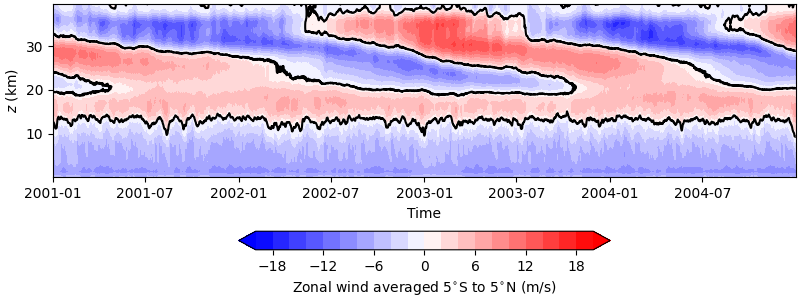

In [4]:
# Zonal wind height vs. time
fig = plt.figure(figsize=(8, 3), constrained_layout=True)

im = plt.contourf(time, zs/1e3, Ubar_t.T, levels=np.linspace(-20, 20, 21), cmap='bwr', extend='both')
plt.contour(time, zs/1e3, Ubar_t.T, levels=[0], colors='k')

fig.colorbar(im, location='bottom', label=r"Zonal wind averaged $5^{\circ}$S to $5^{\circ}$N (m/s)", shrink=0.5)

plt.xlabel("Time")
plt.ylabel(r"$z$ (km)")

In [5]:
def plot_CPT2(Tbar):
    ztps = []
    for i in range(len(lats)):
        ttp, _, ztp, _ = tropopause_profile(Tbar[2:, i].values, np.ones_like(zs[2:]), zs[2:])
        ztps.append(ztp)
    return ztps

Text(0, 0.5, '$z$ (km)')

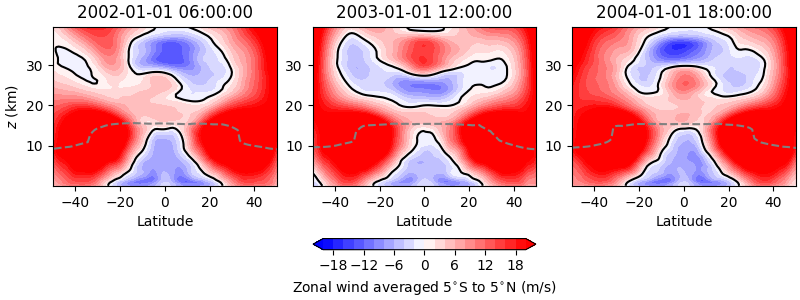

In [6]:
# Latitude vs. height
t_idx = [i*(len(time)//4) for i in range(1, 4)]

fig, axs = plt.subplots(1, len(t_idx), figsize=(8, 3), constrained_layout=True)

for i, t in enumerate(t_idx):
    im = axs[i].contourf(lats, zs/1e3, Ubar[t], levels=np.linspace(-20, 20, 21), cmap='bwr', extend='both')
    axs[i].contour(lats, zs/1e3, Ubar[t], levels=[0], colors='k')
    axs[i].set_xlabel("Latitude")
    axs[i].set_title(time[t])
    axs[i].set_xlim(-50, 50)
    
    ztp = plot_CPT2(Tbar[t])
    axs[i].plot(lats, np.array(ztp)/1e3, color='gray', ls='--')

fig.colorbar(im, location='bottom', ax=axs, label=r"Zonal wind averaged $5^{\circ}$S to $5^{\circ}$N (m/s)", shrink=0.3)

axs[0].set_ylabel(r"$z$ (km)")

/tmp/ipykernel_3600492/2843080621.py:51: UserWarning: Adding colorbar to a different Figure <Figure size 800x450 with 4 Axes> than <Figure size 800x300 with 4 Axes> which fig.colorbar is called on.
  u_cbar = fig.colorbar(u_im, ax=axs[0], location='bottom', shrink=0.8)
/tmp/ipykernel_3600492/2843080621.py:52: UserWarning: Adding colorbar to a different Figure <Figure size 800x450 with 5 Axes> than <Figure size 800x300 with 4 Axes> which fig.colorbar is called on.
  T_cbar = fig.colorbar(T_im, ax=axs[1], location='bottom', shrink=0.8)
/tmp/ipykernel_3600492/2843080621.py:53: UserWarning: Adding colorbar to a different Figure <Figure size 800x450 with 6 Axes> than <Figure size 800x300 with 4 Axes> which fig.colorbar is called on.
  F_cbar = fig.colorbar(EPFD_im, ax=axs[2], location='bottom', shrink=0.8)
/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/matplotlib/quiver.py:676: RuntimeWarning: Mean of empty slice.
  amean = a[~self.Umask].mean()
/alt/applic/user

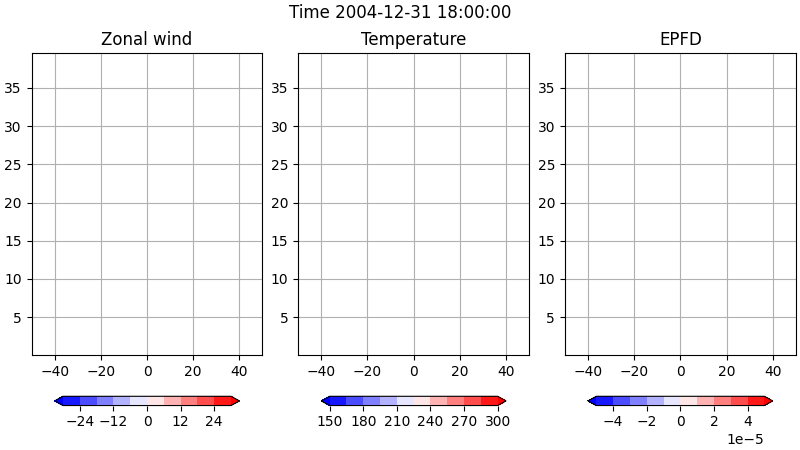

In [7]:
# Animated version of the above
u_levs = np.linspace(-30, 30, 11)
T_levs = np.linspace(150, 300, 11)
F_levs = np.linspace(-5e-5, 5e-5, 11)

a = 6371e3
H = 7e3
aspect = 12/5
deg_to_m = np.pi * a / 180.
vert_scale = 1 / (zs[-1]/1e3 - zs[0]/1e3)
horiz_scale =  aspect / (100. * np.pi / 180.)

n = 5
m = 5

rho0 = 1 * np.exp(-zs[::n]/H)
F_scale = np.outer(1/rho0, 2*np.pi*a*a*np.cos(np.deg2rad(lats[::m])))
Fy_scale = horiz_scale * F_scale / a
Fz_scale = vert_scale * F_scale

def plot(fig, step):
    u_im = axs[0].contourf(lats, zs/1e3, Ubar_rs[step], levels=u_levs, cmap='bwr', extend='both')
    axs[0].contour(lats, zs/1e3, Ubar_rs[step], levels=[0], colors='k', linewidths=1)
    axs[0].set_title("Zonal wind")
    
    T_im = axs[1].contourf(lats, zs/1e3, Tbar_rs[step], levels=T_levs, cmap='bwr', extend='both')
    axs[1].set_title("Temperature")
    
    EPFD_im = axs[2].contourf(lats, zs/1e3, EPFD[step], levels=F_levs, cmap='bwr', extend='both')
    axs[2].quiver(lats[::m] , zs[::n]/1e3, Fy[step, ::n, ::m] * Fy_scale, Fz[step, ::n, ::m] * Fz_scale / 1e3, angles='xy', pivot='mid', scale_units='xy')#, scale=1)
    axs[2].contour(lats, zs/1e3, EPFD[step], levels=[0], colors='k', linewidths=1)
    axs[2].set_title("EPFD")
    
    fig.suptitle("Time {0}".format(time[step]))
    
    ztp = plot_CPT2(Tbar_rs[step])
    for a in axs:
        a.plot(lats, np.array(ztp)/1e3, color='gray', ls='--')

    return T_im, u_im, EPFD_im

def decorate(axs):
    for a in axs:
        a.grid()
        a.set_xlim(-50, 50)

anim_fig, axs = plt.subplots(1, 3, figsize=(8, 4.5), constrained_layout=True)

T_im, u_im, EPFD_im = plot(anim_fig, 0)

u_cbar = fig.colorbar(u_im, ax=axs[0], location='bottom', shrink=0.8)
T_cbar = fig.colorbar(T_im, ax=axs[1], location='bottom', shrink=0.8)
F_cbar = fig.colorbar(EPFD_im, ax=axs[2], location='bottom', shrink=0.8)

decorate(axs)

def animate(step):
    for a in axs:
        a.clear()
    plot(anim_fig, step)
    decorate(axs)

Writer = animation.writers['ffmpeg']
writer = Writer(fps=40, bitrate=-1)
anim = animation.FuncAnimation(anim_fig, animate, interval=5, frames=list(range(len(Ubar_rs))), repeat=True)

save_fig(anim, '/home/cwp29/tmp/mpas/control_long_uTF.mp4', dpi=300, anim=True)

In [8]:
# Animated version of the above
F_levs = np.linspace(-5e-5, 5e-5, 11)
Fh = dst['EPFd_y'].rolling(time=ndays*4, center=True).mean()
Fv = dst['EPFd_z'].rolling(time=ndays*4, center=True).mean()

/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/alt/applic/user-maint/cwp29/Conda/envs/python/lib/python3.11/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


KeyboardInterrupt: 

In [ ]:
def plot(fig, step):
    Fh_im = axs[0].contourf(lats, zs/1e3, Fh[step], levels=F_levs, cmap='bwr', extend='both')
    axs[0].contour(lats, zs/1e3, Fh[step], levels=[0], colors='k', linewidths=1)
    axs[0].set_title("EPFD horiz")
    
    Fv_im = axs[1].contourf(lats, zs/1e3, Fv[step], levels=F_levs, cmap='bwr', extend='both')
    axs[1].contour(lats, zs/1e3, Fv[step], levels=[0], colors='k', linewidths=1)
    axs[1].set_title("EPFD vert")
    
    fig.suptitle("Time {0}".format(time[step]))
    
    ztp = plot_CPT2(Tbar_rs[step])
    for a in axs:
        a.plot(lats, np.array(ztp)/1e3, color='gray', ls='--')

    return Fh_im, Fv_im

def decorate(axs):
    for a in axs:
        a.grid()
        a.set_xlim(-50, 50)

anim_fig, axs = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)

Fh_im, Fv_im = plot(anim_fig, 0)

cbar = fig.colorbar(Fh_im, ax=axs[1], location='right', shrink=0.8)

decorate(axs)

def animate(step):
    for a in axs:
        a.clear()
    plot(anim_fig, step)
    decorate(axs)

Writer = animation.writers['ffmpeg']
writer = Writer(fps=40, bitrate=-1)
anim = animation.FuncAnimation(anim_fig, animate, interval=5, frames=list(range(len(Ubar_rs))), repeat=True)
#plt.show()

save_fig(anim, '/home/cwp29/tmp/mpas/control_long_EPFD_decomp.mp4', dpi=300, anim=True)

In [ ]:
F = dst['EPFd'].sel(latitude=slice(-10, 10))
F = F.weighted(lat_weights)
F_t = F.mean(dim='latitude')

F_t = F_t.rolling(time=ndays*4, center=True).mean()
Ubar_t = Ubar_t.rolling(time=ndays*4, center=True).mean()

In [ ]:
anim_fig2 = plt.figure(figsize=(8, 4), constrained_layout=True)

# Change this to plot du/dt?

uline, = plt.plot(Ubar_t[1000], zs/1e3, color='b', label=r"$\overline{u}$")
Fline, = plt.plot(F_t[1000]*1e6, zs/1e3, color='r', label="EPFD")

plt.ylim(zs[0]/1e3, zs[-1]/1e3)
plt.xlim(1.1*np.nanmin(Ubar_t.values), 1.1*np.nanmax(Ubar_t.values))
plt.axvline(0, color='k', ls='--')

def animate2(step):
    uline.set_xdata(Ubar_t[step])
    Fline.set_xdata(F_t[step]*1e6)
    fig.suptitle("Time {0}".format(time[step]))

    return uline, Fline,

Writer = animation.writers['ffmpeg']
writer = Writer(fps=40, bitrate=-1)

anim2 = animation.FuncAnimation(anim_fig2, animate2, interval=20, frames=list(range(0, len(F_t))), repeat=True)
plt.show()

save_fig(anim2, '/home/cwp29/tmp/mpas/control_long_profile.mp4', dpi=300, anim=True)